# Showing the data via scanpy

In [2]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd

In [30]:
sc.__version__

'1.9.8'

In [18]:
adata = sc.read_h5ad("../data/scrnaseq_atlas.h5ad")
print(adata)

AnnData object with n_obs × n_vars = 30850 × 64955
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mtdna', 'percent.rrna', 'percent.goodgenes', 'seurat_clusters', 'S.Score', 'G2M.Score', 'Phase', 'clade_coarse_nj', 'vic_annotations', 'year_end_annotation_2022.coarse', 'cell_barcode', 'curated_48hpf.derived_annotations', 'biological_replicate', 'whitelisted_for_curation', 'nCount_SCT', 'nFeature_SCT', 'curated_high_res_annotations', 'coarse_clade_membership', 'celltype_family_20240924', 'group_full', 'group_slug', 'group_color', 'clade', 'subclade', 'subsubclade'
    uns: 'version'
    obsm: 'X_pca', 'X_umap'
    layers: 'RNA'


I have a 'RNA' layers instead of counts.

In [19]:
adata.layers['counts'] = adata.layers.pop('RNA')
adata.X = adata.layers['counts'].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

I do not need to redo the dimensionality reduction process, I saved it from Seurat...

/home/buglakov/miniconda3/envs/scrnaseq/lib/python3.12/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/home/buglakov/miniconda3/envs/scrnaseq/lib/python3.12/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


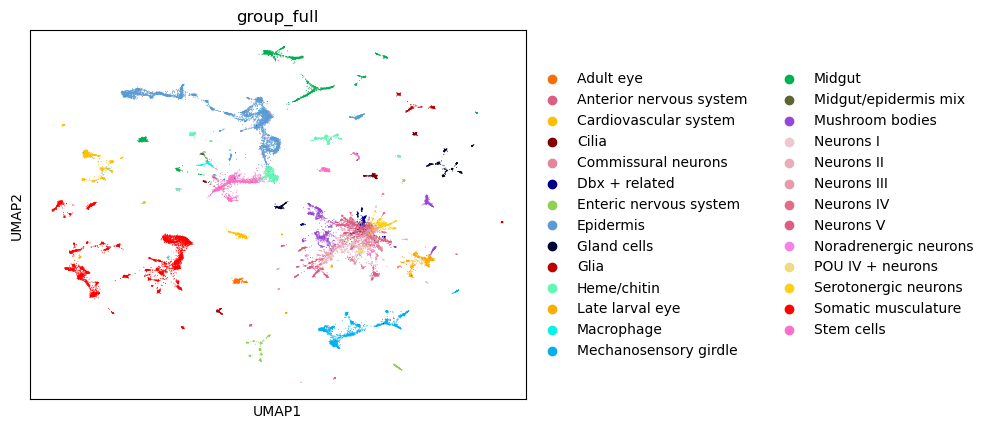

In [20]:
# I already have a defined color map
palette_dict = pd.Series(adata.obs['group_color'].values, index=adata.obs['group_full']).to_dict()
sc.pl.umap(
    adata,
    color="group_full",
    palette=palette_dict,
    size=2,
)

**In terms of metadata we care about:**
* `curated_high_res_annotations`:  Detlev's ~250 cell types (except 3 he likes but that are not in this curated object)
* `group_full`: Detlev's 20 or so big grouping, neurons are a bit hazy

I will rename my features to `XLOC | symbol`.

In [24]:
genes_metadata = pd.read_csv("../data/gene_metadata.tsv", sep="\t")
genes_metadata

,Unnamed: 0,ProsPR gene,Published name,pdumV2-1,Platybrowser name,XLOC,XLOC_full
0,0,Glt1,Glt1,XLOC_001410,glt1,XLOC-001410,XLOC-001410 | glt1
1,1,AChE,AChE,XLOC_027437,ache,XLOC-027437,XLOC-027437 | ache
2,2,ANPRA,NaN,XLOC_025950,anpra,XLOC-025950,XLOC-025950 | anpra
3,4,AP2,ap2,XLOC_002429,ap2,XLOC-002429,XLOC-002429 | ap2
4,5,ASCb,ASCb,XLOC_008377,ascb,XLOC-008377,XLOC-008377 | ascb
...,...,...,...,...,...,...,...
172,197,brn124,NaN,XLOC_005393,brn124,XLOC-005393,XLOC-005393 | brn124
173,198,nompc3,NaN,XLOC_002090,nompc3,XLOC-002090,XLOC-002090 | nompc3
174,199,pkd1,PKD1-1,XLOC_027897,pkd1,XLOC-027897,XLOC-027897 | pkd1
175,200,pkd2,PKD2-1,XLOC_026080,pkd2,XLOC-026080,XLOC-026080 | pkd2


In [25]:
genes_lookup = dict(zip(genes_metadata['XLOC'], genes_metadata['XLOC_full']))
genes_lookup

{'XLOC-001410': 'XLOC-001410 | glt1',
 'XLOC-027437': 'XLOC-027437 | ache',
 'XLOC-025950': 'XLOC-025950 | anpra',
 'XLOC-002429': 'XLOC-002429 | ap2',
 'XLOC-008377': 'XLOC-008377 | ascb',
 'XLOC-022100': 'XLOC-022100 | allcr1',
 'XLOC-025660': 'XLOC-025660 | allcr2',
 'XLOC-044659': 'XLOC-044659 | arx',
 'XLOC-004258': 'XLOC-004258 | ash',
 'XLOC-056544': 'XLOC-056544 | barh1',
 'XLOC-003898': 'XLOC-003898 | beta3',
 'XLOC-009861': 'XLOC-009861 | bmpr1',
 'XLOC-000129': 'XLOC-000129 | brn3a',
 'XLOC-028320': 'XLOC-028320 | coe',
 'XLOC-026597': 'XLOC-026597 | chat',
 'XLOC-021496': 'XLOC-021496 | chx10',
 'XLOC-003551': 'XLOC-003551 | dach',
 'XLOC-018534': 'XLOC-018534 | dbhlike',
 'XLOC-020366': 'XLOC-020366 | dopard2',
 'XLOC-053880': 'XLOC-053880 | pgam',
 'XLOC-015543': 'XLOC-015543 | upp',
 'XLOC-008954': 'XLOC-008954 | unc22',
 'XLOC-014514': 'XLOC-014514 | ndus1',
 'XLOC-021313': 'XLOC-021313 | odo2',
 'XLOC-018549': 'XLOC-018549 | fxl21',
 'XLOC-012281': 'XLOC-012281 | ryr2'

I only keep Platybrowser features and I make sure I don't have unknown XLOC.

In [26]:
assert(not set(genes_lookup.keys()).difference(set(adata.var_names.to_list())))
subset_adata = adata[:, adata.var_names.isin(genes_lookup.keys())].copy()
subset_adata

AnnData object with n_obs × n_vars = 30850 × 175
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mtdna', 'percent.rrna', 'percent.goodgenes', 'seurat_clusters', 'S.Score', 'G2M.Score', 'Phase', 'clade_coarse_nj', 'vic_annotations', 'year_end_annotation_2022.coarse', 'cell_barcode', 'curated_48hpf.derived_annotations', 'biological_replicate', 'whitelisted_for_curation', 'nCount_SCT', 'nFeature_SCT', 'curated_high_res_annotations', 'coarse_clade_membership', 'celltype_family_20240924', 'group_full', 'group_slug', 'group_color', 'clade', 'subclade', 'subsubclade'
    uns: 'version', 'log1p', 'group_full_colors'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'

In [27]:
subset_adata.var['XLOC'] = subset_adata.var_names
subset_adata.var_names = subset_adata.var_names.to_series().map(genes_lookup).tolist()

In [28]:
print(subset_adata.var_names)

Index(['XLOC-000033 | hand', 'XLOC-000129 | brn3a', 'XLOC-000131 | trk',
       'XLOC-000375 | hcn1', 'XLOC-000555 | gcb', 'XLOC-000718 | kv33b',
       'XLOC-000791 | nov29', 'XLOC-000875 | syt', 'XLOC-000971 | twist',
       'XLOC-001169 | ppib',
       ...
       'XLOC-064375 | bca1', 'XLOC-064638 | gpcr203', 'XLOC-066432 | vegfr',
       'XLOC-067105 | grm7', 'XLOC-067814 | rims', 'XLOC-067936 | psmf1',
       'XLOC-068990 | kv33e', 'XLOC-069315 | trpv5', 'XLOC-026293 | ato2',
       'XLOC-043332 | gpcr2'],
      dtype='object', length=175)


Pseudobulking is done like this:

In [29]:
platybrowser_aggregated = sc.get.aggregate(subset_adata, 
                                           by=["group_full", "curated_high_res_annotations"], 
                                           func=["sum", "count_nonzero"],layer="counts")
platybrowser_aggregated

AttributeError: module 'scanpy.get' has no attribute 'aggregate'

I will do a giant dotplot of what we have for Platybrowser. Let's define some arguments we want to play with from https://scanpy.readthedocs.io/en/stable/api/generated/classes/scanpy.pl.DotPlot.html
I will reuse them later.

In [31]:
extra_args = {
    "expression_cutoff": 0,
    "standard_scale": "group", # None #  "var"
    "mean_only_expressed": False
}

You get the big group names and the the clades. We could play with the order, but not for now. Some markers are super high everywhere, others like `unc-22` are good markers for a group like `Somatic musculature`. Some are super sparse.

/home/buglakov/miniconda3/envs/scrnaseq/lib/python3.12/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/home/buglakov/miniconda3/envs/scrnaseq/lib/python3.12/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/home/buglakov/miniconda3/envs/scrnaseq/lib/python3.12/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored

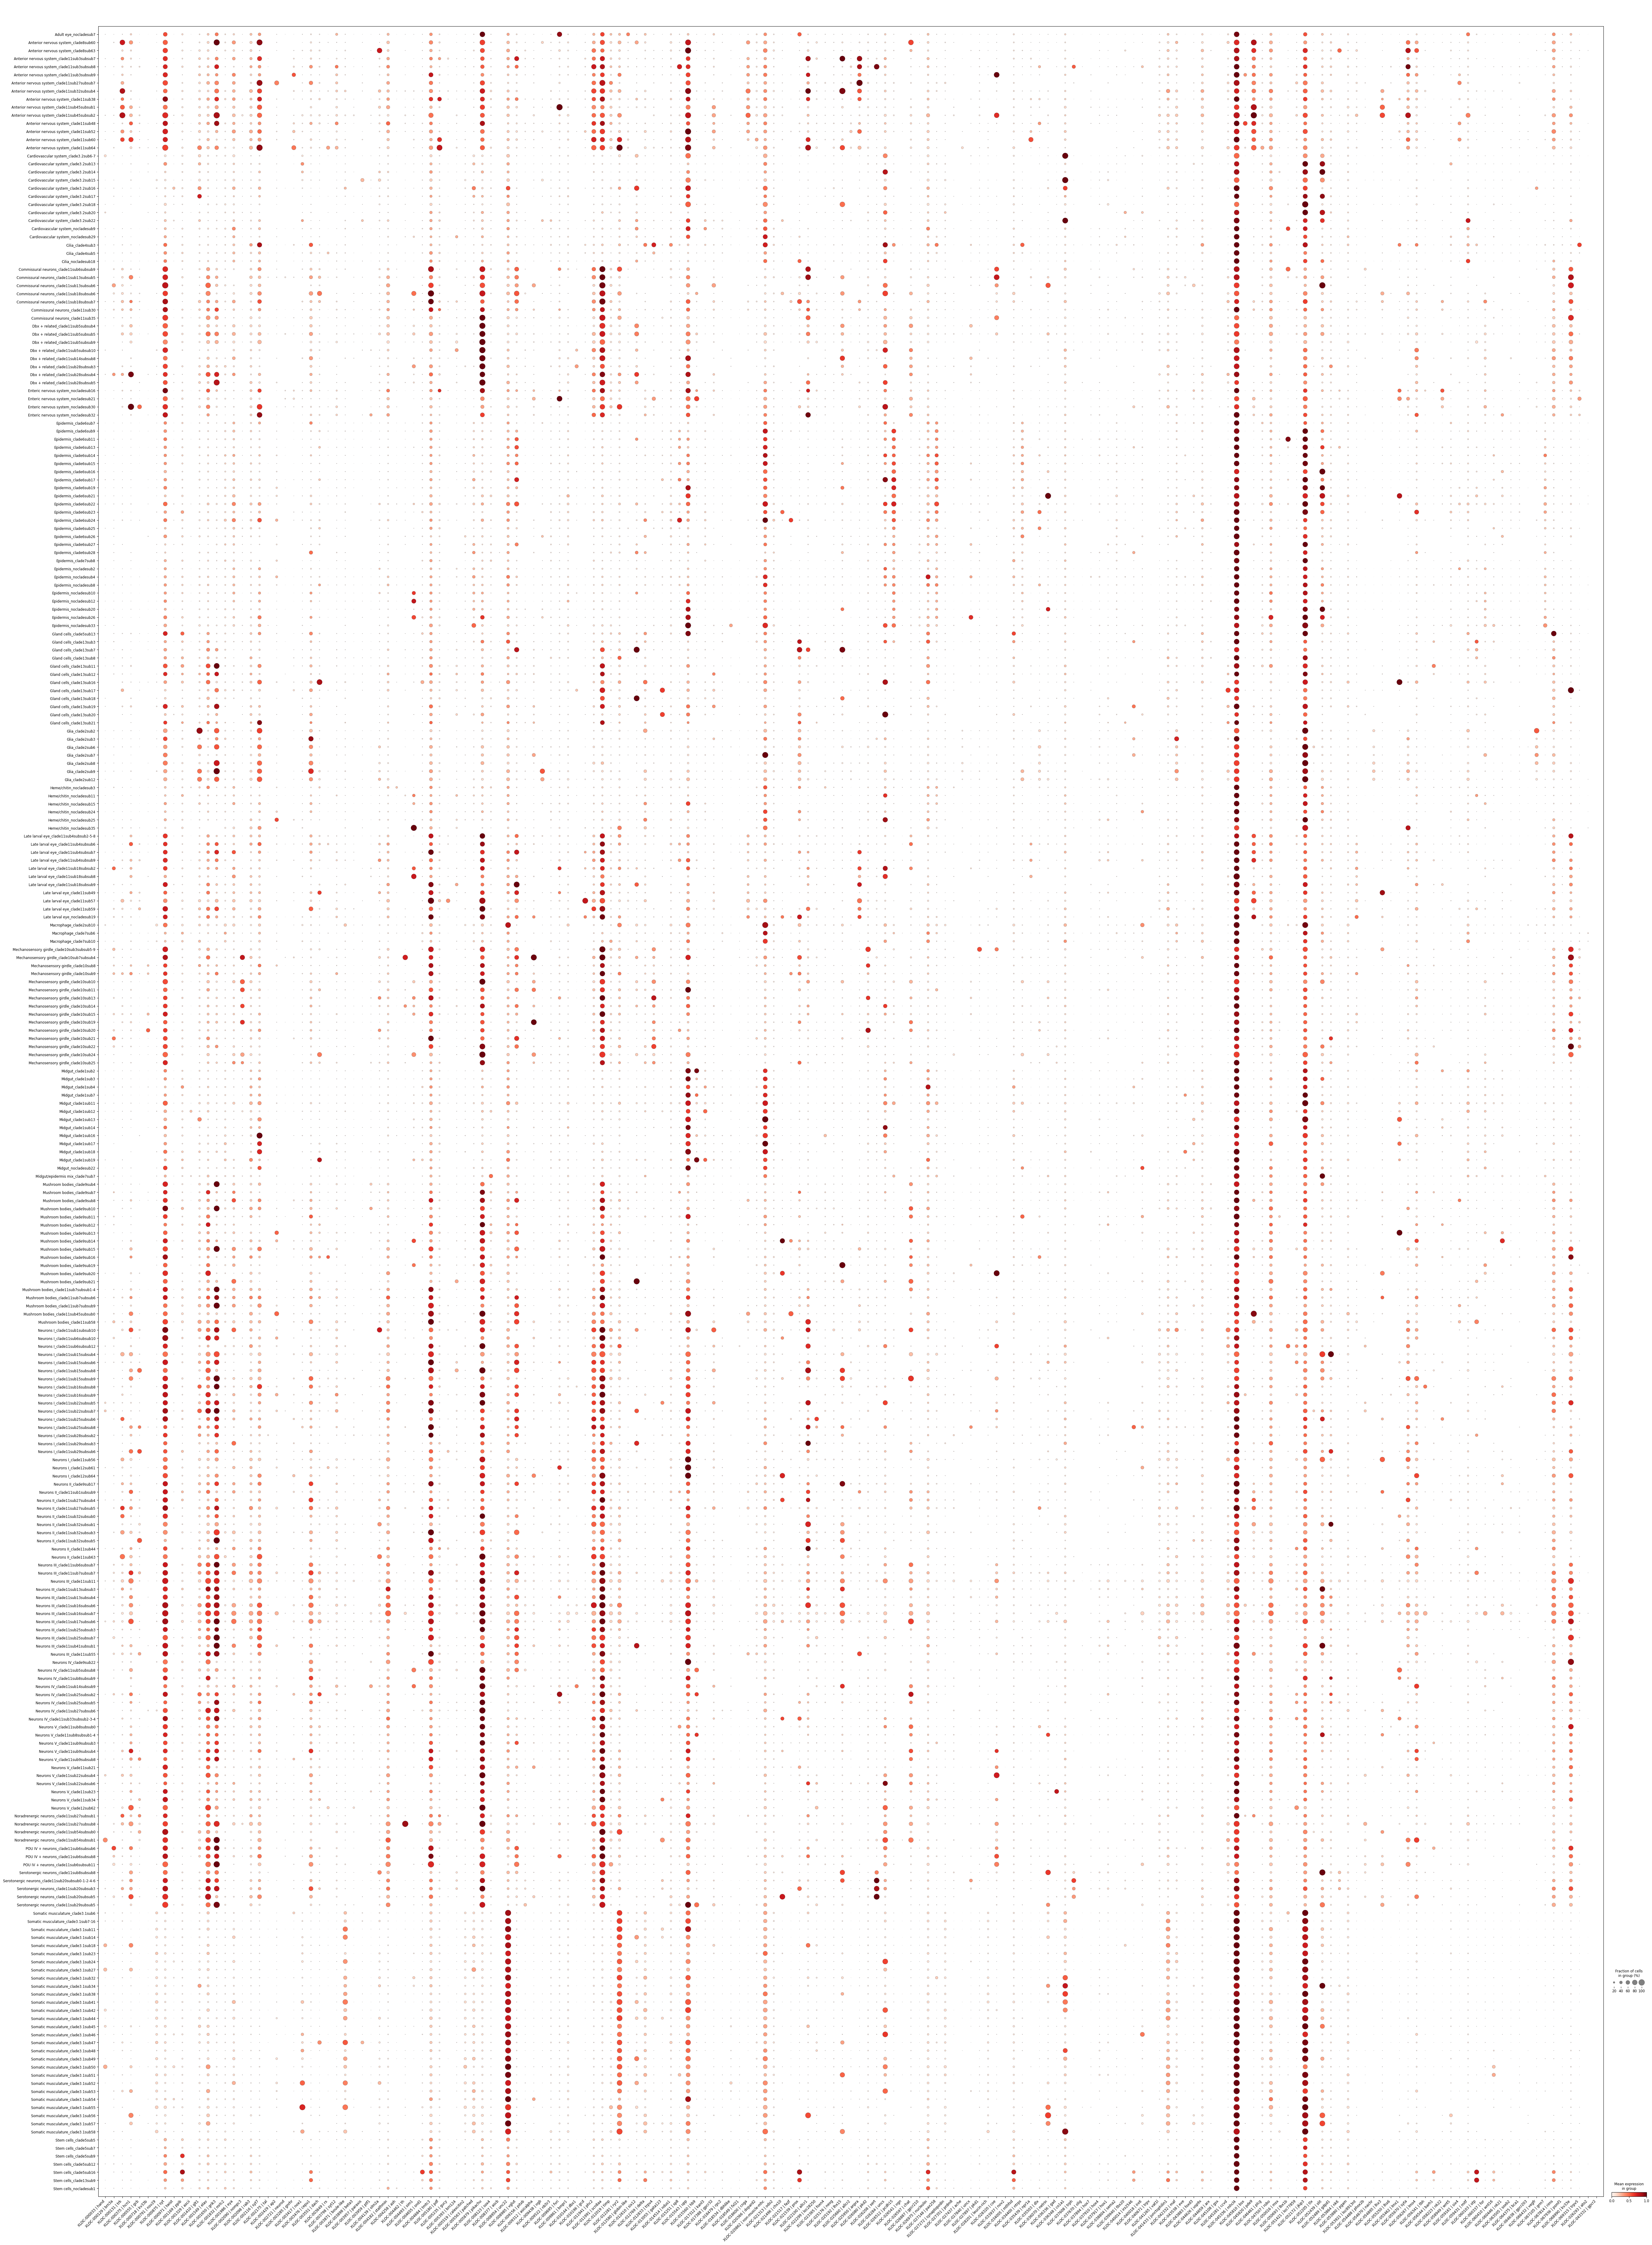

In [32]:
platybrowser_dotplot = sc.pl.dotplot(
    subset_adata, 
    subset_adata.var_names.to_list(),
    groupby=["group_full", "curated_high_res_annotations"],
    return_fig=True,
    **extra_args
)

# Prettier plots
platybrowser_dotplot .make_figure()
ax = platybrowser_dotplot .get_axes()['mainplot_ax']
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.show()

We can access info from the dotplot.

In [33]:
platybrowser_dotplot = sc.pl.dotplot(
    subset_adata, 
    subset_adata.var_names.to_list(),
    groupby=["group_full", "curated_high_res_annotations"], 
    return_fig=True,
    **extra_args
)

/home/buglakov/miniconda3/envs/scrnaseq/lib/python3.12/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/home/buglakov/miniconda3/envs/scrnaseq/lib/python3.12/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()


Following https://github.com/scverse/scanpy/blob/1.11.3/src/scanpy/plotting/_dotplot.py#L822-L1031 I can extract the dotplot information

In [34]:
obs_bool = platybrowser_dotplot.obs_tidy > extra_args["expression_cutoff"]

# dot_size -> fraction of cells, never changes
dot_size_df = (
    obs_bool.groupby(level=0, observed=True).sum()
        / obs_bool.groupby(level=0, observed=True).count()
)

# dot_color -> strength of expression but with scaled values, scaling can change!
if extra_args["mean_only_expressed"]:
    dot_color_df = (
        platybrowser_dotplot.obs_tidy.mask(~obs_bool)
            .groupby(level=0, observed=True)
            .mean()
            .fillna(0)
        )
else:
    dot_color_df = platybrowser_dotplot.obs_tidy.groupby(level=0, observed=True).mean()

# dot_color depends on the chosen scale
standard_scale = extra_args["standard_scale"]
if standard_scale == "group":
    dot_color_df = dot_color_df.sub(dot_color_df.min(1), axis=0)
    dot_color_df = dot_color_df.div(dot_color_df.max(1), axis=0).fillna(0)
elif standard_scale == "var":
    dot_color_df -= dot_color_df.min(0)
    dot_color_df = (dot_color_df / dot_color_df.max(0)).fillna(0)
elif standard_scale is None:
    pass
else:
    print("Unknown type for standard_scale, ignored")

Here is what you end up with:

In [35]:
dot_color_df.head()   # mean of SCALED expression value

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5,XLOC-026293 | ato2,XLOC-043332 | gpcr2
group_full_curated_high_res_annotations,,,,,,,,,,,,,,,,,,,,,
Adult eye_nocladesub7,0.022198,0.015248,0.042993,0.169736,0.005995,0.001405,0.018079,0.578787,0.004623,0.149039,...,0.024629,0.004966,0.007503,0.020178,0.376029,0.019368,0.229301,0.007010,0.001754,0.0
Anterior nervous system_clade8sub60,0.000000,0.036712,0.746187,0.354410,0.006493,0.000000,0.007643,0.530321,0.000000,0.057879,...,0.013768,0.000000,0.000000,0.012104,0.314606,0.013147,0.064020,0.000000,0.000000,0.0
Anterior nervous system_clade8sub63,0.000000,0.000000,0.130882,0.117175,0.000000,0.000000,0.000000,0.618841,0.000000,0.091991,...,0.000000,0.000000,0.029157,0.031141,0.329229,0.012698,0.044490,0.028472,0.016313,0.0
Anterior nervous system_clade11sub3subsub7,0.036154,0.007014,0.396268,0.135287,0.012570,0.000000,0.007308,0.676243,0.008495,0.095452,...,0.006528,0.007055,0.000000,0.000000,0.291035,0.007055,0.051407,0.030602,0.000000,0.0
Anterior nervous system_clade11sub3subsub8,0.035521,0.021395,0.156105,0.103161,0.105439,0.000000,0.028565,0.706278,0.000000,0.140166,...,0.064383,0.013651,0.016149,0.015453,0.328186,0.038648,0.124772,0.012037,0.000000,0.0


In [36]:
dot_size_df.head()  # Fraction of cells expressing

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5,XLOC-026293 | ato2,XLOC-043332 | gpcr2
group_full_curated_high_res_annotations,,,,,,,,,,,,,,,,,,,,,
Adult eye_nocladesub7,0.030043,0.019313,0.051502,0.197425,0.008584,0.002146,0.021459,0.622318,0.006438,0.180258,...,0.034335,0.006438,0.008584,0.025751,0.442060,0.027897,0.272532,0.010730,0.002146,0.0
Anterior nervous system_clade8sub60,0.000000,0.076923,0.830769,0.553846,0.015385,0.000000,0.015385,0.753846,0.000000,0.092308,...,0.030769,0.000000,0.000000,0.030769,0.507692,0.030769,0.123077,0.000000,0.000000,0.0
Anterior nervous system_clade8sub63,0.000000,0.000000,0.189189,0.162162,0.000000,0.000000,0.000000,0.783784,0.000000,0.162162,...,0.000000,0.000000,0.054054,0.054054,0.513514,0.027027,0.054054,0.054054,0.027027,0.0
Anterior nervous system_clade11sub3subsub7,0.042105,0.010526,0.421053,0.168421,0.021053,0.000000,0.010526,0.736842,0.010526,0.115789,...,0.010526,0.010526,0.000000,0.000000,0.368421,0.010526,0.073684,0.042105,0.000000,0.0
Anterior nervous system_clade11sub3subsub8,0.035714,0.035714,0.178571,0.125000,0.125000,0.000000,0.035714,0.696429,0.000000,0.196429,...,0.071429,0.017857,0.017857,0.017857,0.392857,0.053571,0.178571,0.017857,0.000000,0.0


In [37]:
average_absolute_exp = pd.DataFrame(
    platybrowser_aggregated.layers['sum'],
    index=platybrowser_aggregated.obs_names,
    columns=platybrowser_aggregated.var_names
)

average_absolute_exp.head()

NameError: name 'platybrowser_aggregated' is not defined